# Chapter 29: The distance field

Checks [chapter 29](../../book/29-the-distance-field.md). The curves are sines of amplitude one, `sin(frequency * x)`, so the slope
limit equals the frequency and the amplitude never changes. The field is the distance to the polyline through 600 000 samples of the
curve on `[-6, 6]`, computed exactly segment by segment, so it is a distance to a set and the claims about sets apply to it. The model is not
trained: the theorems are about the field of a given curve. These are measurements, not proofs: the proofs are in `SignedDistance.lean`
and `Eikonal.lean`. Run every cell, top to bottom. A failed check stops the notebook.

In [1]:
import sys
sys.path.append("../part1")

import numpy as np
from scipy.spatial import cKDTree
import matplotlib.pyplot as plt
from common import use_style, save_figure, report, NEAREST, VERTICAL, BOUND, MODEL, BEFORE

use_style()
SEED = 29
SAMPLE_COUNT = 600_000
SEGMENTS_EACH_SIDE = 3


class Curve:
    """A sine curve of amplitude one, and the exact distance field of the polyline through its samples."""

    def __init__(self, frequency):
        self.frequency = frequency
        self.slope_limit = float(frequency)
        sample_inputs = np.linspace(-6.0, 6.0, SAMPLE_COUNT)
        self.vertices = np.stack([sample_inputs, self.get_height(sample_inputs)], axis=1)
        self.tree = cKDTree(self.vertices)

    def get_height(self, inputs):
        return np.sin(self.frequency * inputs)

    def get_slope(self, inputs):
        return self.frequency * np.cos(self.frequency * inputs)

    def get_nearest_point(self, points):
        """The nearest point of the polyline to each point, found on the segments next to the nearest vertex."""
        points = np.atleast_2d(points)
        _, vertex_index = self.tree.query(points)
        best_distance = np.full(len(points), np.inf)
        best_point = np.zeros_like(points)
        for offset in range(-SEGMENTS_EACH_SIDE, SEGMENTS_EACH_SIDE):
            start_index = np.clip(vertex_index + offset, 0, len(self.vertices) - 2)
            start = self.vertices[start_index]
            step = self.vertices[start_index + 1] - start
            along = np.einsum("ij,ij->i", points - start, step) / np.einsum("ij,ij->i", step, step)
            foot = start + np.clip(along, 0.0, 1.0)[:, None] * step
            distance = np.linalg.norm(points - foot, axis=1)
            better = distance < best_distance
            best_distance = np.where(better, distance, best_distance)
            best_point = np.where(better[:, None], foot, best_point)
        return best_point

    def get_field(self, points):
        points = np.atleast_2d(points)
        return np.linalg.norm(points - self.get_nearest_point(points), axis=1)

    def get_signed_field(self, points):
        points = np.atleast_2d(points)
        above = np.sign(points[:, 1] - self.get_height(points[:, 0]))
        return above * self.get_field(points)

    def get_vertical_error(self, points):
        points = np.atleast_2d(points)
        return np.abs(points[:, 1] - self.get_height(points[:, 0]))


def make_points(generator, count, half_width=3.0, half_height=1.5):
    return np.stack([generator.uniform(-half_width, half_width, count),
                     generator.uniform(-half_height, half_height, count)], axis=1)


CURVES = {frequency: Curve(frequency) for frequency in (1, 2, 5, 10, 20, 40)}
print("curves built, frequencies", list(CURVES))

curves built, frequencies [1, 2, 5, 10, 20, 40]


## Claim 1: the example by hand (the line `y = 3x`)

The chapter says: at `(0, 1)` the field is `1 / sqrt(10)`, about 0.316, with nearest point `(0.3, 0.9)`; at `(1, 0)` it is 0.949 and the signed
distance is negative; halfway from `(0, 1)` to `(0.3, 0.9)` the field is 0.158; the height 1 divided by `sqrt(1 + 3^2)` equals the field.
Predicted: the program, which knows only the polyline, gives these numbers to within `1e-9`. It would count against the chapter if the nearest
point were anywhere else. The line is built as a two-point polyline from `x = -3` to `3`.

In [2]:
line_curve = Curve.__new__(Curve)
line_curve.frequency = 3.0
line_curve.get_height = lambda inputs: 3.0 * inputs
line_curve.vertices = np.array([[-3.0, -9.0], [3.0, 9.0]])
line_curve.tree = cKDTree(line_curve.vertices)

above_point = np.array([[0.0, 1.0]])
below_point = np.array([[1.0, 0.0]])
nearest = line_curve.get_nearest_point(above_point)[0]
field_above = line_curve.get_field(above_point)[0]
field_below = line_curve.get_field(below_point)[0]
halfway = above_point[0] + 0.5 * (nearest - above_point[0])
field_halfway = line_curve.get_field(halfway[None, :])[0]
signed_above = line_curve.get_signed_field(above_point)[0]
signed_below = line_curve.get_signed_field(below_point)[0]
print(f"nearest point {nearest}, field above {field_above:.6f}, field below {field_below:.6f}, field halfway {field_halfway:.6f}")
report("the nearest point of (0, 1) is (0.3, 0.9)", np.abs(nearest - [0.3, 0.9]).max() < 1e-9, f"nearest {nearest}")
report("the field at (0, 1) is 1 / sqrt(10)", abs(field_above - 1 / np.sqrt(10)) < 1e-9, f"field {field_above:.6f}")
report("the field at (1, 0) is 3 / sqrt(10) and its signed value is negative",
       abs(field_below - 3 / np.sqrt(10)) < 1e-9 and signed_below < 0 < signed_above, f"signed {signed_below:.6f}")
report("halfway to the nearest point the field is half", abs(field_halfway - 0.5 * field_above) < 1e-9, f"field {field_halfway:.6f}")
report("the height divided by sqrt(1 + 3^2) is the field", abs(1.0 / np.sqrt(10) - field_above) < 1e-9)

nearest point [0.3 0.9], field above 0.316228, field below 0.948683, field halfway 0.158114
[PASS] the nearest point of (0, 1) is (0.3, 0.9)  (nearest [0.3 0.9])
[PASS] the field at (0, 1) is 1 / sqrt(10)  (field 0.316228)
[PASS] the field at (1, 0) is 3 / sqrt(10) and its signed value is negative  (signed -0.948683)
[PASS] halfway to the nearest point the field is half  (field 0.158114)
[PASS] the height divided by sqrt(1 + 3^2) is the field


True

## Claim 2: the field is never steep, however squiggly the curve is (`lipschitzWith_distanceField`)

For each of the six curves (frequencies 1 to 40, amplitude one in every case) take 5 000 pairs of points of the plane, the second a distance
`gap` from the first, with `gap` drawn log-uniformly between `1e-3` and `0.5`, in a random direction, and 5 000 more along the direction of fastest fall (toward the nearest point). Predicted: the largest ratio
`|field(second) - field(first)| / gap` is at most one for every curve, to within `1e-4` (that margin covers the polyline's rounding at the smallest gap). The
control is the vertical error, the height above the curve read as a function of the plane: its ratio is `sqrt(1 + slope^2)` along its steepest direction, so it should reach about the slope
limit for the steep curves. Pairs for the vertical error are taken a distance `1e-4` apart along its gradient direction, because its steep
direction is narrow. The claim fails if a field ratio exceeds `1 + 1e-4`. Next to each field ratio the notebook prints the vertical one, as the loss sees only that.

In [3]:
generator = np.random.default_rng(SEED)
PAIR_COUNT = 5_000
GAP_VERTICAL = 1e-4
field_ratio_max = {}
vertical_ratio_max = {}
for frequency, curve in CURVES.items():
    first = make_points(generator, PAIR_COUNT)
    gaps = np.exp(generator.uniform(np.log(1e-3), np.log(0.5), PAIR_COUNT))
    angles = generator.uniform(0, 2 * np.pi, PAIR_COUNT)
    second = first + gaps[:, None] * np.stack([np.cos(angles), np.sin(angles)], axis=1)
    random_ratio = np.abs(curve.get_field(second) - curve.get_field(first)) / gaps
    toward = curve.get_nearest_point(first) - first          # the direction in which the field falls fastest
    toward_unit = toward / np.linalg.norm(toward, axis=1)[:, None]
    toward_ratio = np.abs(curve.get_field(first + gaps[:, None] * toward_unit) - curve.get_field(first)) / gaps
    field_ratio_max[frequency] = max(random_ratio.max(), toward_ratio.max())
    above = np.sign(first[:, 1] - curve.get_height(first[:, 0]))
    gradient = np.stack([-curve.get_slope(first[:, 0]), np.ones(PAIR_COUNT)], axis=1) * above[:, None]
    gradient_unit = gradient / np.linalg.norm(gradient, axis=1)[:, None]
    vertical_step = first + GAP_VERTICAL * gradient_unit
    vertical_ratio_max[frequency] = (np.abs(curve.get_vertical_error(vertical_step) - curve.get_vertical_error(first)) / GAP_VERTICAL).max()
    print(f"frequency {frequency:>2}: largest field ratio {field_ratio_max[frequency]:.6f}   largest vertical-error ratio {vertical_ratio_max[frequency]:.3f}"
          f"   sqrt(1 + slope_limit^2) = {np.sqrt(1 + curve.slope_limit ** 2):.3f}")

worst_field = max(field_ratio_max.values())
report("the field ratio is at most one for all six curves", worst_field <= 1 + 1e-4, f"largest over all curves {worst_field:.6f}")
report("control: the vertical error is steep on the steep curves (ratio above 0.9 of the slope limit at frequency 40)",
       vertical_ratio_max[40] > 0.9 * 40, f"ratio {vertical_ratio_max[40]:.2f} against slope limit 40")
report("the vertical error never beats its own bound sqrt(1 + slope_limit^2)",
       all(vertical_ratio_max[frequency] <= np.sqrt(1 + frequency ** 2) + 1e-3 for frequency in CURVES))

frequency  1: largest field ratio 1.000000   largest vertical-error ratio 1.414   sqrt(1 + slope_limit^2) = 1.414


frequency  2: largest field ratio 1.000000   largest vertical-error ratio 2.236   sqrt(1 + slope_limit^2) = 2.236


frequency  5: largest field ratio 1.000000   largest vertical-error ratio 5.099   sqrt(1 + slope_limit^2) = 5.099


frequency 10: largest field ratio 1.000000   largest vertical-error ratio 10.050   sqrt(1 + slope_limit^2) = 10.050
frequency 20: largest field ratio 1.000000   largest vertical-error ratio 20.025   sqrt(1 + slope_limit^2) = 20.025


frequency 40: largest field ratio 1.000000   largest vertical-error ratio 40.012   sqrt(1 + slope_limit^2) = 40.012
[PASS] the field ratio is at most one for all six curves  (largest over all curves 1.000000)
[PASS] control: the vertical error is steep on the steep curves (ratio above 0.9 of the slope limit at frequency 40)  (ratio 40.01 against slope limit 40)
[PASS] the vertical error never beats its own bound sqrt(1 + slope_limit^2)


True

## Claim 3: walking toward the nearest point, the field falls by exactly what you walk (`infDist_toward_nearest`)

For each of the six curves take 2 000 random points, a random `fraction` in `[0, 1]`, and walk that fraction of the way to the nearest point.
Predicted: `field(walked point) = (1 - fraction) * field(start)` to within `1e-7`. This would fail if the foot
of the walk were not a nearest point. The control walks the same fraction toward the point of the curve straight above or below the start (the vertical foot),
which is a point of the curve but not the nearest. Predicted: the rule then fails for most walks, because that walk is longer than the nearest distance and the field falls by less than the length walked.
The measure is the fall of the field divided by the length walked: it is exactly one for the nearest point, so the control would count as a failure for the claim if most of its ratios were one. The check is that more than 90 percent
of the control walks have a ratio below 0.999 on every curve. (The first version of this control asked for the field to be *above* the rule by an absolute 0.05 on the steep curves. That was a wrong prediction:
the walk is longer, so the field can also land below the rule, and on steep curves all the distances are small. It was replaced by the ratio, before the claim was rerun, and no threshold was loosened.) The vertical error is printed next to the nearest distance.

In [4]:
generator = np.random.default_rng(SEED + 1)
walk_gap = {}
control_off_rule = {}
control_median_ratio = {}
control_largest_gap = {}
for frequency, curve in CURVES.items():
    start = make_points(generator, 2000)
    fractions = generator.uniform(0, 1, 2000)
    start_field = curve.get_field(start)
    nearest_point = curve.get_nearest_point(start)
    walked = start + fractions[:, None] * (nearest_point - start)
    walk_gap[frequency] = np.abs(curve.get_field(walked) - (1 - fractions) * start_field).max()
    foot = np.stack([start[:, 0], curve.get_height(start[:, 0])], axis=1)
    control_walked = start + fractions[:, None] * (foot - start)
    control_field = curve.get_field(control_walked)
    length_walked = np.linalg.norm(control_walked - start, axis=1)
    fall_ratio = (start_field - control_field) / length_walked
    control_off_rule[frequency] = (fall_ratio < 0.999).mean()
    control_median_ratio[frequency] = np.median(fall_ratio)
    control_largest_gap[frequency] = (np.abs(control_field - (1 - fractions) * start_field) / start_field).max()
    vertical_over_nearest = (curve.get_vertical_error(start) / start_field).max()
    print(f"frequency {frequency:>2}: largest gap from (1 - fraction) * field {walk_gap[frequency]:.1e};  control: {100 * control_off_rule[frequency]:.1f} percent of walks off the rule, "
          f"median fall per unit walked {control_median_ratio[frequency]:.3f}, largest relative gap {control_largest_gap[frequency]:.2f}; vertical error up to {vertical_over_nearest:.1f} times the nearest distance")
report("the field after the walk is (1 - fraction) * field before, 6 curves, 12 000 walks",
       max(walk_gap.values()) < 1e-7, f"largest gap {max(walk_gap.values()):.1e}")
report("control: toward the vertical foot, more than 90 percent of walks fall by less than the length walked, on every curve",
       min(control_off_rule.values()) > 0.9, f"smallest share {min(control_off_rule.values()):.3f}")
report("control: on the steepest curve the median fall per unit walked is far below one",
       control_median_ratio[40] < 0.5, f"median {control_median_ratio[40]:.3f} at frequency 40")

frequency  1: largest gap from (1 - fraction) * field 4.4e-16;  control: 98.7 percent of walks off the rule, median fall per unit walked 0.758, largest relative gap 0.06; vertical error up to 1.4 times the nearest distance


frequency  2: largest gap from (1 - fraction) * field 4.4e-16;  control: 99.7 percent of walks off the rule, median fall per unit walked 0.501, largest relative gap 0.14; vertical error up to 2.2 times the nearest distance


frequency  5: largest gap from (1 - fraction) * field 4.4e-16;  control: 99.5 percent of walks off the rule, median fall per unit walked 0.245, largest relative gap 0.24; vertical error up to 5.1 times the nearest distance
frequency 10: largest gap from (1 - fraction) * field 3.1e-16;  control: 99.3 percent of walks off the rule, median fall per unit walked 0.129, largest relative gap 0.41; vertical error up to 10.0 times the nearest distance
frequency 20: largest gap from (1 - fraction) * field 6.2e-16;  control: 98.4 percent of walks off the rule, median fall per unit walked 0.066, largest relative gap 0.56; vertical error up to 20.0 times the nearest distance
frequency 40: largest gap from (1 - fraction) * field 3.9e-16;  control: 97.0 percent of walks off the rule, median fall per unit walked 0.033, largest relative gap 0.67; vertical error up to 40.0 times the nearest distance
[PASS] the field after the walk is (1 - fraction) * field before, 6 curves, 12 000 walks  (largest gap 6.

True

## Claim 4: no slope limit below one works (`not_lipschitzWith_infDist_of_lt_one`)

Walk all the way to the nearest point (`fraction = 1`) from 2 000 random points on each curve. The field falls from its starting value to zero while
the walk has exactly that length. Predicted: the fall divided by the length walked is one to within `1e-7`, and the end of the walk has field below `1e-6`.
A slope limit of 0.5 would need that ratio to be at most 0.5. It would count against the chapter if the ratio were below one anywhere.

In [5]:
generator = np.random.default_rng(SEED + 2)
ratio_gap = 0.0
end_field = 0.0
lowest_ratio = np.inf
for frequency, curve in CURVES.items():
    start = make_points(generator, 2000)
    nearest_point = curve.get_nearest_point(start)
    length_walked = np.linalg.norm(nearest_point - start, axis=1)
    fall = curve.get_field(start) - curve.get_field(nearest_point)
    valid = length_walked > 1e-3
    ratios = fall[valid] / length_walked[valid]
    ratio_gap = max(ratio_gap, np.abs(ratios - 1).max())
    lowest_ratio = min(lowest_ratio, ratios.min())
    end_field = max(end_field, curve.get_field(nearest_point).max())
report("the fall equals the length walked, on all six curves", ratio_gap < 1e-7, f"largest distance of the ratio from one {ratio_gap:.1e}")
report("the end of the walk is on the curve", end_field < 1e-6, f"largest field at the end {end_field:.1e}")
report("a slope limit of 0.5 is forbidden: the smallest ratio is above 0.5", lowest_ratio > 0.5, f"smallest ratio {lowest_ratio:.6f}")

[PASS] the fall equals the length walked, on all six curves  (largest distance of the ratio from one 5.2e-14)
[PASS] the end of the walk is on the curve  (largest field at the end 4.4e-16)
[PASS] a slope limit of 0.5 is forbidden: the smallest ratio is above 0.5  (smallest ratio 1.000000)


True

## Claim 5: a step as long as the field cannot reach the curve, and the height over `sqrt(1 + slope_limit^2)` is safe (`notMem_curve_of_dist_lt`, `notMem_curve_of_dist_lt_verticalDist_div`)

For frequencies 5 and 20 take 3 000 random points. From each, step in a random direction within 60 degrees of straight toward the curve (down if above it, up if below)
by three step lengths: the field, the vertical error divided by `sqrt(1 + slope_limit^2)`, and the vertical error alone. Along each step, test 200 points for a change of side
of the curve (above to below or the reverse). Predicted: no crossing for the first two lengths. The third is the control, the unsafe step of the chapter: some steps should
cross, and the fraction that does is reported. A crossing of the first two would count against the claim.

In [6]:
generator = np.random.default_rng(SEED + 3)
crossing_rate = {}
for frequency in (5, 20):
    curve = CURVES[frequency]
    start = make_points(generator, 3000)
    side = np.sign(start[:, 1] - curve.get_height(start[:, 0]))
    angle = generator.uniform(-np.pi / 3, np.pi / 3, 3000)
    direction = np.stack([np.sin(angle), -side * np.cos(angle)], axis=1)
    field = curve.get_field(start)
    vertical = curve.get_vertical_error(start)
    lengths = {"field": field, "height over sqrt(1 + slope_limit^2)": vertical / np.sqrt(1 + curve.slope_limit ** 2), "height": vertical}
    for name, length in lengths.items():
        crossed = np.zeros(3000, dtype=bool)
        for fraction in np.linspace(0.005, 1.0, 200):
            probe = start + (fraction * length)[:, None] * direction
            probe_side = np.sign(probe[:, 1] - curve.get_height(probe[:, 0]))
            crossed |= probe_side * side < 0
        crossing_rate[(frequency, name)] = crossed.mean()
        print(f"frequency {frequency:>2}, step = {name:<38}: {int(crossed.sum()):>4} of 3000 steps crossed the curve")
report("steps as long as the field never cross", all(crossing_rate[(frequency, "field")] == 0 for frequency in (5, 20)))
report("steps of height over sqrt(1 + slope_limit^2) never cross",
       all(crossing_rate[(frequency, "height over sqrt(1 + slope_limit^2)")] == 0 for frequency in (5, 20)))
report("control: steps as long as the height do cross on the steep curve", crossing_rate[(20, "height")] > 0.05,
       f"{crossing_rate[(20, 'height')]:.3f} of steps at frequency 20")

frequency  5, step = field                                 :    0 of 3000 steps crossed the curve
frequency  5, step = height over sqrt(1 + slope_limit^2)   :    0 of 3000 steps crossed the curve
frequency  5, step = height                                : 2015 of 3000 steps crossed the curve


frequency 20, step = field                                 :    0 of 3000 steps crossed the curve
frequency 20, step = height over sqrt(1 + slope_limit^2)   :    0 of 3000 steps crossed the curve
frequency 20, step = height                                : 2463 of 3000 steps crossed the curve
[PASS] steps as long as the field never cross
[PASS] steps of height over sqrt(1 + slope_limit^2) never cross
[PASS] control: steps as long as the height do cross on the steep curve  (0.821 of steps at frequency 20)


True

## Claim 6: the field is zero on the curve, and the slope sandwich (`distanceField_eq_zero_iff`, `abs_signedDist_le_verticalDist`, `verticalDist_le_abs_signedDist`)

Take 5 000 points exactly on each curve: the field must be zero (to within `1e-6`, the chord error of the polyline), where the vertical error is also zero.
Then take 5 000 random points off the curve and check both halves of the sandwich:
`nearest <= vertical <= sqrt(1 + slope_limit^2) * nearest`, with a margin of `1e-6` for the polyline. The largest `vertical / nearest` is printed against the bound, so the claim could
fail if the vertical error were ever larger than the bound allows.

In [7]:
generator = np.random.default_rng(SEED + 4)
on_curve_field = 0.0
lower_violation = -np.inf
upper_violation = -np.inf
for frequency, curve in CURVES.items():
    inputs = generator.uniform(-3, 3, 5000)
    on_curve = np.stack([inputs, curve.get_height(inputs)], axis=1)
    on_curve_field = max(on_curve_field, curve.get_field(on_curve).max())
    points = make_points(generator, 5000)
    nearest_distance = np.abs(curve.get_signed_field(points))
    vertical_error = curve.get_vertical_error(points)
    lower_violation = max(lower_violation, (nearest_distance - vertical_error).max())
    upper_violation = max(upper_violation, (vertical_error - np.sqrt(1 + curve.slope_limit ** 2) * nearest_distance).max())
    print(f"frequency {frequency:>2}: largest vertical / nearest {(vertical_error / nearest_distance).max():8.3f}   bound sqrt(1 + slope_limit^2) {np.sqrt(1 + curve.slope_limit ** 2):8.3f}")
report("the field is zero on the curve", on_curve_field < 1e-6, f"largest field on the curve {on_curve_field:.1e}")
report("nearest distance <= vertical error", lower_violation < 1e-6, f"largest excess {lower_violation:.1e}")
report("vertical error <= sqrt(1 + slope_limit^2) * nearest distance", upper_violation < 1e-6, f"largest excess {upper_violation:.1e}")

frequency  1: largest vertical / nearest    1.414   bound sqrt(1 + slope_limit^2)    1.414


frequency  2: largest vertical / nearest    2.236   bound sqrt(1 + slope_limit^2)    2.236


frequency  5: largest vertical / nearest    5.099   bound sqrt(1 + slope_limit^2)    5.099
frequency 10: largest vertical / nearest   10.050   bound sqrt(1 + slope_limit^2)   10.050
frequency 20: largest vertical / nearest   20.025   bound sqrt(1 + slope_limit^2)   20.025
frequency 40: largest vertical / nearest   40.010   bound sqrt(1 + slope_limit^2)   40.012
[PASS] the field is zero on the curve  (largest field on the curve 8.0e-08)
[PASS] nearest distance <= vertical error  (largest excess 4.8e-08)
[PASS] vertical error <= sqrt(1 + slope_limit^2) * nearest distance  (largest excess -3.3e-09)


True

## Figure 1: the field of one curve, with the nearest points

The field of `sin(4 x)` as a filled contour, with eight seeded sample points. From each, a black line to its nearest point of the curve (the nearest distance, which is the field)
and a dotted orange line straight to the curve (the vertical error, which is what the loss sees). The creases of the field are where the shade changes direction between two arches.

the sample points: nearest distance, vertical error
  (-2.58, +0.07): 0.199, 0.707
  (+1.94, +1.58): 0.579, 0.585
  (-1.34, +1.40): 0.425, 0.596
  (+0.79, +0.60): 0.155, 0.605
  (-0.08, +0.89): 0.324, 1.212
  (+1.50, -1.09): 0.280, 0.814
  (+1.98, +1.25): 0.253, 0.255
  (+2.08, +1.70): 0.707, 0.802


wrote book/figures/29-distance-field.png


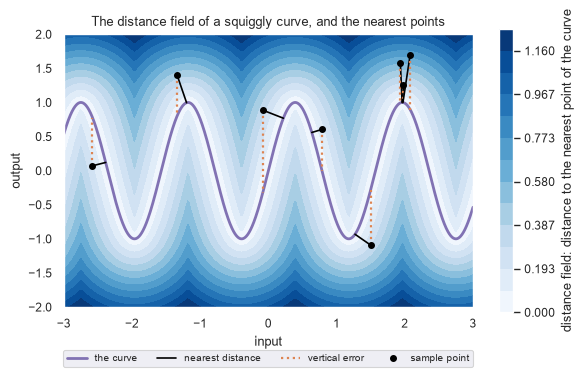

In [8]:
curve = Curve(4)
generator = np.random.default_rng(SEED + 5)
grid_inputs = np.linspace(-3, 3, 361)
grid_outputs = np.linspace(-2, 2, 241)
mesh_x, mesh_y = np.meshgrid(grid_inputs, grid_outputs)
mesh_points = np.stack([mesh_x.ravel(), mesh_y.ravel()], axis=1)
field_values = curve.get_field(mesh_points).reshape(mesh_x.shape)
sample_points = make_points(generator, 8, half_width=2.6, half_height=1.7)
nearest_points = curve.get_nearest_point(sample_points)
print("the sample points: nearest distance, vertical error")
for point, near in zip(sample_points, nearest_points):
    print(f"  ({point[0]:+.2f}, {point[1]:+.2f}): {np.linalg.norm(point - near):.3f}, {abs(point[1] - np.sin(4 * point[0])):.3f}")

figure, axis = plt.subplots(figsize=(6.6, 4.6))
filled = axis.contourf(mesh_x, mesh_y, field_values, levels=np.linspace(0, field_values.max(), 14), cmap="Blues")
figure.colorbar(filled, ax=axis, label="distance field: distance to the nearest point of the curve", shrink=0.8)
curve_inputs = np.linspace(-3, 3, 1500)
axis.plot(curve_inputs, curve.get_height(curve_inputs), color=MODEL, linewidth=2, label="the curve")
for index, (point, near) in enumerate(zip(sample_points, nearest_points)):
    axis.plot([point[0], near[0]], [point[1], near[1]], color="black", linewidth=1.2, label="nearest distance" if index == 0 else None)
    axis.plot([point[0], point[0]], [point[1], np.sin(4 * point[0])], color=VERTICAL, linestyle=":", linewidth=1.6, label="vertical error" if index == 0 else None)
axis.plot(sample_points[:, 0], sample_points[:, 1], "o", color="black", markersize=4, label="sample point")
axis.set_aspect("equal")
axis.set_xlim(-3, 3)
axis.set_ylim(-2, 2)
axis.set_xlabel("input")
axis.set_ylabel("output")
axis.set_title("The distance field of a squiggly curve, and the nearest points")
axis.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=4, fontsize=7)
save_figure(figure, "29-distance-field")
plt.show()

## Figure 2: the field's steepest slope against the curve's slope limit

For each of the six curves, the largest ratio measured in claim 2, for the field (blue) and for the vertical error (orange), against the curve's slope limit. The green lines are the proved bounds:
one for the field and `sqrt(1 + slope_limit^2)` for the vertical error. The measured field ratio is at most one for every curve; the vertical error follows its own, rising, bound.

wrote book/figures/29-slope-of-the-field.png


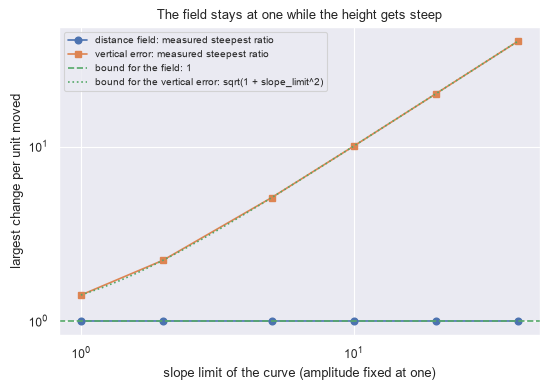

In [9]:
slope_limits = np.array(list(CURVES))
figure, axis = plt.subplots(figsize=(6.2, 4.0))
axis.plot(slope_limits, [field_ratio_max[key] for key in CURVES], "o-", color=NEAREST, label="distance field: measured steepest ratio")
axis.plot(slope_limits, [vertical_ratio_max[key] for key in CURVES], "s-", color=VERTICAL, label="vertical error: measured steepest ratio")
axis.axhline(1.0, color=BOUND, linestyle="--", label="bound for the field: 1")
bound_inputs = np.linspace(1, 40, 200)
axis.plot(bound_inputs, np.sqrt(1 + bound_inputs ** 2), color=BOUND, linestyle=":", label="bound for the vertical error: sqrt(1 + slope_limit^2)")
axis.set_xscale("log")
axis.set_yscale("log")
axis.set_xlabel("slope limit of the curve (amplitude fixed at one)")
axis.set_ylabel("largest change per unit moved")
axis.set_title("The field stays at one while the height gets steep")
axis.legend(loc="upper left", fontsize=7)
save_figure(figure, "29-slope-of-the-field")
plt.show()